# 2.3 — Gaussian and Laplacian Pyramids

Build Gaussian and Laplacian pyramids **from scratch**

- Blur kernel: $\frac{1}{16}\,[1,\,4,\,6,\,4,\,1]$ applied separably along x and y.
- `reduce`: blur, then keep every other row/column.
- `expand`: place each pixel at the top-left of a 2×2 zero block, blur, multiply by 4.
- Reconstruct by walking the Laplacian pyramid from the coarsest level up.
- Discuss exactness and the Gaussian pyramid's total size.

## 0 — Theory

### kernel

$$k = \frac{1}{16}\,[1,\;4,\;6,\;4,\;1]$$

### reduce

$$G_{n+1} = (G_n * k\,k^\top)_{\downarrow 2}$$

### expand

$$\text{expand}(J) = 4 \cdot \bigl(\text{upsample}_2(J) * k\,k^\top\bigr)$$

### Gaussian pyramid

$$G_0 = I, \qquad G_{n+1} = \text{reduce}(G_n)$$

### Laplacian pyramid

$$L_n = G_n - \text{expand}(G_{n+1}), \qquad L_L = G_L$$

### Reconstruction

$$\hat{G}_L = L_L, \qquad \hat{G}_n = L_n + \text{expand}(\hat{G}_{n+1})$$

**Important:** the Laplacian levels $L_0, \dots, L_{L-1}$ are **signed residuals** centered on 0, whereas $L_L$ is an **actual image** (the coarsest Gaussian). They must be displayed differently.

## 1 — Environment setup

In [14]:
from pathlib import Path
import sys
# %pip install "numpy<2" --force-reinstall
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
IMAGE_DIR = ROOT / "starter_pack" / "images" / "part2_frequencies"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

from starter_pack.code.utils import load_image

plt.rcParams["figure.dpi"] = 100

In [15]:
KERNEL_1D = np.array([1, 4, 6, 4, 1], dtype=np.float32) / 16.0


def _convolve_1d_reflect(image, kernel, axis):
    radius = len(kernel) // 2
    if axis == 0:
        padded = np.pad(image, ((radius, radius), (0, 0)), mode="reflect")
        out = np.empty_like(image, dtype=np.float32)
        for r in range(image.shape[0]):
            out[r] = np.sum(padded[r:r + len(kernel)] * kernel[:, None], axis=0)
    elif axis == 1:
        padded = np.pad(image, ((0, 0), (radius, radius)), mode="reflect")
        out = np.empty_like(image, dtype=np.float32)
        for c in range(image.shape[1]):
            out[:, c] = np.sum(padded[:, c:c + len(kernel)] * kernel[None, :], axis=1)
    else:
        raise ValueError("axis must be 0 or 1")
    return out


def blur_binomial(image):
    """Apply the 5-tap kernel [1 4 6 4 1]/16 along x then y.
    Works for 2-D (H,W) or 3-D (H,W,C) images."""
    if image.ndim == 2:
        return _convolve_1d_reflect(
            _convolve_1d_reflect(image, KERNEL_1D, axis=1), KERNEL_1D, axis=0
        )
    channels = [
        _convolve_1d_reflect(
            _convolve_1d_reflect(image[:, :, c], KERNEL_1D, axis=1),
            KERNEL_1D, axis=0,
        )
        for c in range(image.shape[2])
    ]
    return np.stack(channels, axis=2)

## 2 — `reduce` and `expand`

In [16]:
def reduce_image(image):
    """Blur with the 5-tap kernel, then keep every other row and column."""
    return blur_binomial(image)[::2, ::2]


def expand_image(image, target_shape=None):
    """Place each pixel at the top-left of a 2x2 zero block, blur, multiply by 4.

    If `target_shape` is given (h, w) or (h, w, c), crop the result to that shape.
    This handles odd sizes: expand may produce one row/column too many.
    """
    if image.ndim == 2:
        H, W = image.shape
        up = np.zeros((2 * H, 2 * W), dtype=np.float32)
        up[::2, ::2] = image
        out = 4.0 * blur_binomial(up)
    else:
        H, W, C = image.shape
        up = np.zeros((2 * H, 2 * W, C), dtype=np.float32)
        up[::2, ::2, :] = image
        out = 4.0 * blur_binomial(up)

    if target_shape is not None:
        th, tw = target_shape[0], target_shape[1]
        out = out[:th, :tw, ...] if out.ndim == 3 else out[:th, :tw]
    return out

## 3 — Load the image

We load `high_frequency.png` and crop to a size whose sides are **not** powers of 2 (so the odd-size branch of `reduce`/`expand` is exercised).

Loaded: shape=(1031, 687, 3), dtype=float32
Working size: (513, 641, 3)  (not a power of 2)


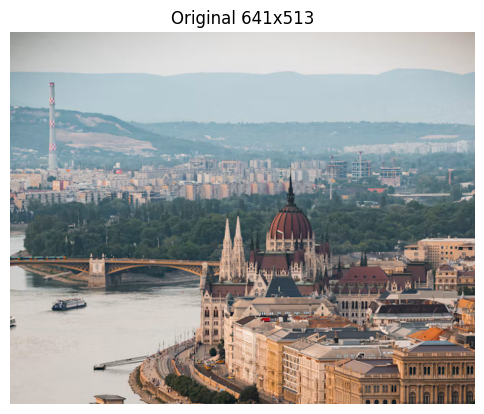

In [17]:
image = load_image(IMAGE_DIR / "high_frequency.png")
print(f"Loaded: shape={image.shape}, dtype={image.dtype}")


def crop_to_non_power_of_two(img, target_h=513, target_w=641):
    h = min(img.shape[0], target_h)
    w = min(img.shape[1], target_w)
    def is_pow2(n): return n > 0 and (n & (n - 1)) == 0
    if is_pow2(h) and is_pow2(w):
        h -= 1
    return img[:h, :w]


image = crop_to_non_power_of_two(image, 513, 641)
print(f"Working size: {image.shape}  (not a power of 2)")

plt.figure(figsize=(6, 6))
plt.imshow(np.clip(image, 0, 1))
plt.title(f"Original {image.shape[1]}x{image.shape[0]}")
plt.axis("off")
plt.show()

## 4 — Gaussian pyramid

In [18]:
def build_gaussian_pyramid(image, min_side=16):
    levels = [image.astype(np.float32)]
    while min(levels[-1].shape[:2]) > min_side:
        levels.append(reduce_image(levels[-1]))
    return levels


gaussian_pyramid = build_gaussian_pyramid(image, min_side=16)
print("Gaussian pyramid levels:")
for i, g in enumerate(gaussian_pyramid):
    print(f"  G{i}: shape={g.shape}")

Gaussian pyramid levels:
  G0: shape=(513, 641, 3)
  G1: shape=(257, 321, 3)
  G2: shape=(129, 161, 3)
  G3: shape=(65, 81, 3)
  G4: shape=(33, 41, 3)
  G5: shape=(17, 21, 3)
  G6: shape=(9, 11, 3)


## 5 — Laplacian pyramid

$$L_n = G_n - \text{expand}(G_{n+1}) \quad (n < L), \qquad L_L = G_L$$

The **coarsest level $L_L$ is a real image**, not a residual. All the other $L_n$ are signed residuals centered near 0.

In [19]:
def build_laplacian_pyramid(gaussian_pyramid):
    L = []
    for n in range(len(gaussian_pyramid) - 1):
        G_n = gaussian_pyramid[n]
        G_next = gaussian_pyramid[n + 1]
        expanded = expand_image(G_next, target_shape=G_n.shape)
        L.append(G_n - expanded)
    L.append(gaussian_pyramid[-1])  # coarsest level: the real image
    return L


laplacian_pyramid = build_laplacian_pyramid(gaussian_pyramid)
print("Laplacian pyramid levels:")
for i, l in enumerate(laplacian_pyramid):
    kind = "residual (signed, ~0)" if i < len(laplacian_pyramid) - 1 else "coarse image"
    print(f"  L{i}: shape={l.shape}  min={l.min():.4f}  max={l.max():.4f}  ({kind})")

Laplacian pyramid levels:
  L0: shape=(513, 641, 3)  min=-0.5806  max=0.5045  (residual (signed, ~0))
  L1: shape=(257, 321, 3)  min=-0.4258  max=0.3199  (residual (signed, ~0))
  L2: shape=(129, 161, 3)  min=-0.2975  max=0.3296  (residual (signed, ~0))
  L3: shape=(65, 81, 3)  min=-0.2136  max=0.2514  (residual (signed, ~0))
  L4: shape=(33, 41, 3)  min=-0.2242  max=0.2202  (residual (signed, ~0))
  L5: shape=(17, 21, 3)  min=-0.1984  max=0.1840  (residual (signed, ~0))
  L6: shape=(9, 11, 3)  min=0.2490  max=0.8699  (coarse image)


## 6 — Reconstruction

$$\hat{G}_L = L_L, \qquad \hat{G}_n = L_n + \text{expand}(\hat{G}_{n+1})$$

Crop to $L_n$'s shape at each step to handle odd sides.

In [20]:
def reconstruct_from_laplacian(laplacian_pyramid):
    current = laplacian_pyramid[-1]
    for n in range(len(laplacian_pyramid) - 2, -1, -1):
        target = laplacian_pyramid[n].shape
        expanded = expand_image(current, target_shape=target)
        current = laplacian_pyramid[n] + expanded
    return current


reconstructed = reconstruct_from_laplacian(laplacian_pyramid)
print(f"Reconstructed shape: {reconstructed.shape}")
print(f"Original shape:      {image.shape}")

Reconstructed shape: (513, 641, 3)
Original shape:      (513, 641, 3)


## 7 — Display the Gaussian pyramid

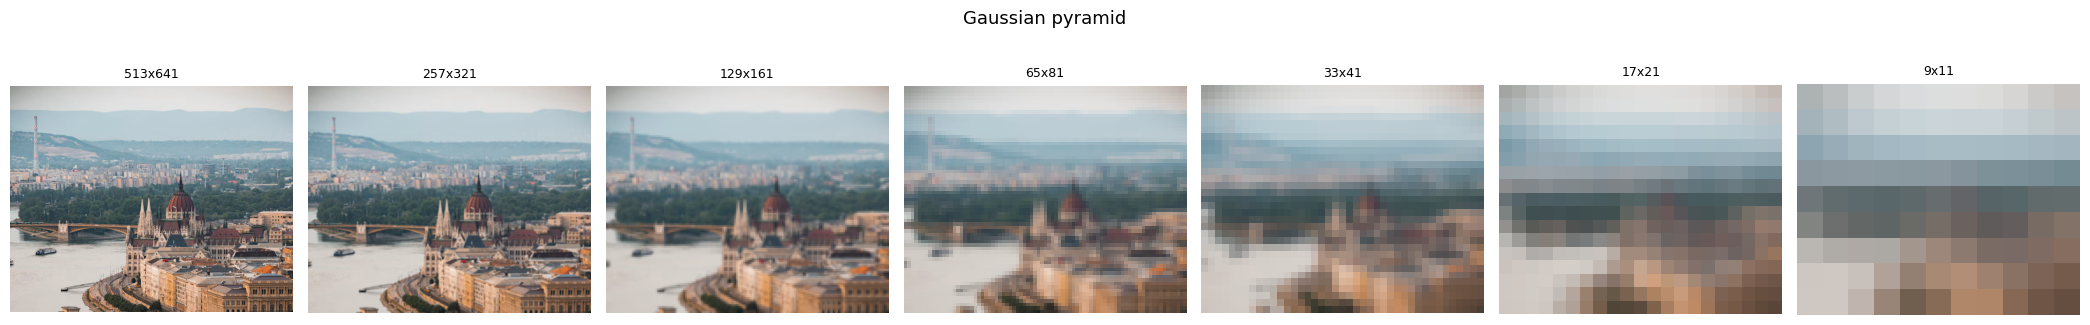

In [21]:
def show_pyramid_grid(levels, title, mode="image", gain=4.0, max_panels=7):
    """Render a pyramid as a horizontal strip.

    mode="image"     -> display each level as a regular image in [0,1]
    mode="residual"  -> display signed residuals with 0.5 + gain*L (clip [0,1])
    mode="mixed"     -> residual for all levels except the last, which is image
    """
    levels = list(levels)[:max_panels]
    n = len(levels)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 3.6))
    if n == 1:
        axes = [axes]

    for i, (ax, lvl) in enumerate(zip(axes, levels)):
        is_last = (i == n - 1)
        if mode == "image":
            img = np.clip(lvl, 0, 1)
        elif mode == "residual":
            img = np.clip(0.5 + gain * lvl, 0, 1)
        elif mode == "mixed":
            if is_last:
                img = np.clip(lvl, 0, 1)
            else:
                img = np.clip(0.5 + gain * lvl, 0, 1)
        else:
            raise ValueError("mode must be 'image', 'residual', or 'mixed'")

        ax.imshow(img)
        ax.set_title(f"{lvl.shape[0]}x{lvl.shape[1]}", fontsize=9)
        ax.axis("off")

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


show_pyramid_grid(gaussian_pyramid, "Gaussian pyramid", mode="image")

## 8 — Display the Laplacian pyramid (contrast boosted)

**Key fix vs. the naive version:** residuals are centered at 0 (not 0.5), so the correct boost is

$$\text{display} = 0.5 + \text{gain} \cdot L$$

and the **coarsest level is an actual image**, displayed normally. If you used the old formula `0.5 + gain*(L-0.5)`, every residual panel appeared black because `L ≈ 0` was subtracted from 0.5 first, then amplified around the wrong center.

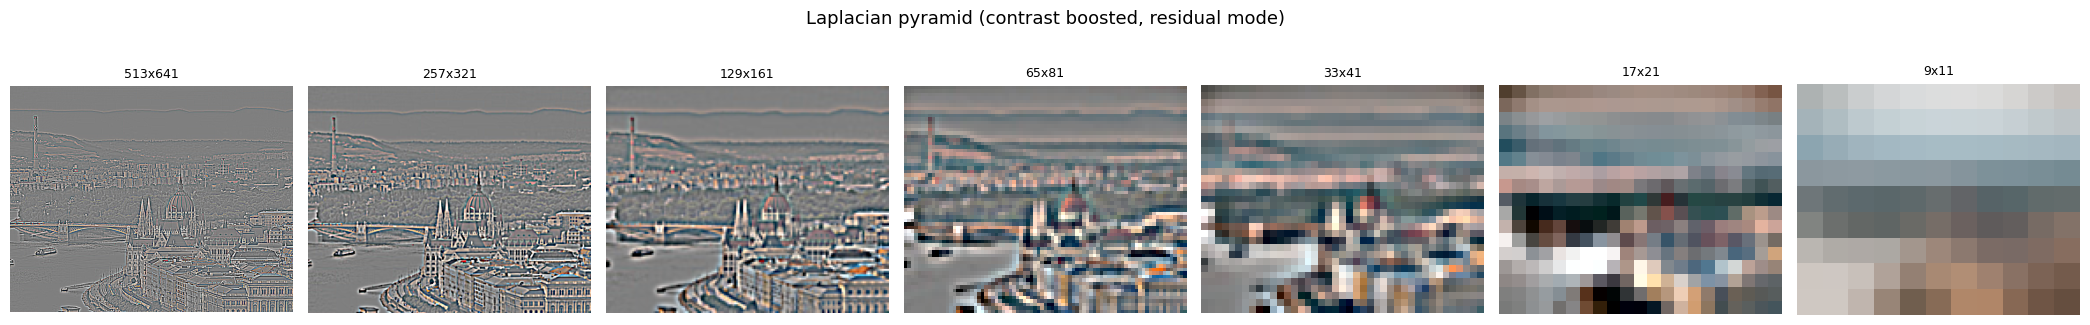

In [22]:
show_pyramid_grid(laplacian_pyramid, "Laplacian pyramid (contrast boosted, residual mode)",
                  mode="mixed", gain=4.0)

In [23]:
# Sanity check: print per-level dynamic range so you can confirm the residual levels
# are signed and near 0, and the coarsest level looks like an image.
for i, lvl in enumerate(laplacian_pyramid):
    is_last = (i == len(laplacian_pyramid) - 1)
    tag = "coarse image" if is_last else "residual"
    print(f"L{i}: shape={lvl.shape}  min={lvl.min(): .4f}  max={lvl.max(): .4f}  mean={lvl.mean(): .4f}  [{tag}]")

L0: shape=(513, 641, 3)  min=-0.5806  max= 0.5045  mean= 0.0000  [residual]
L1: shape=(257, 321, 3)  min=-0.4258  max= 0.3199  mean=-0.0000  [residual]
L2: shape=(129, 161, 3)  min=-0.2975  max= 0.3296  mean=-0.0001  [residual]
L3: shape=(65, 81, 3)  min=-0.2136  max= 0.2514  mean=-0.0002  [residual]
L4: shape=(33, 41, 3)  min=-0.2242  max= 0.2202  mean=-0.0005  [residual]
L5: shape=(17, 21, 3)  min=-0.1984  max= 0.1840  mean=-0.0008  [residual]
L6: shape=(9, 11, 3)  min= 0.2490  max= 0.8699  mean= 0.5954  [coarse image]


## 9 — Reconstruction and error

Max  |error| = 5.960e-08
Mean |error| = 2.806e-11


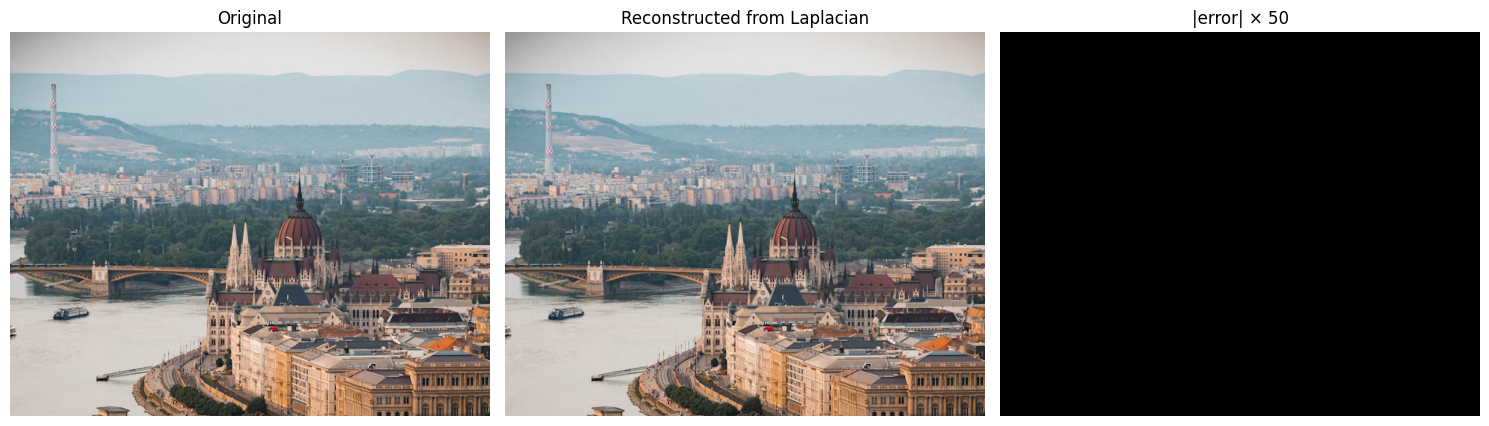

In [24]:
error = np.abs(reconstructed - image)
print(f"Max  |error| = {error.max():.3e}")
print(f"Mean |error| = {error.mean():.3e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(np.clip(image, 0, 1))
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(np.clip(reconstructed, 0, 1))
axes[1].set_title("Reconstructed from Laplacian")
axes[1].axis("off")

axes[2].imshow(np.clip(error * 50.0, 0, 1), cmap="hot")
axes[2].set_title("|error| × 50")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## 10 — Total size of the Gaussian pyramid

For an $H \times W$ image, level $k$ has approximately $HW/4^k$ pixels, so

$$
S = HW \sum_{k=0}^{L} \frac{1}{4^k} \;\to\; HW \cdot \frac{1}{1 - 1/4} = \frac{4}{3}\,HW.
$$

The whole pyramid costs only ~33% more than the original image. Our measured ratio is slightly less than $4/3$ because we stop at `min_side=16` (the tail of the series is truncated).

In [25]:
H0, W0 = image.shape[:2]
per_level_pixels = [g.shape[0] * g.shape[1] for g in gaussian_pyramid]
total_pixels = sum(per_level_pixels)
original_pixels = H0 * W0

print(f"Original size: {H0} x {W0}  ({original_pixels:,} pixels)")
for i, p in enumerate(per_level_pixels):
    print(f"  G{i}: {gaussian_pyramid[i].shape[0]} x {gaussian_pyramid[i].shape[1]}  ({p:,} pixels)")
print(f"\nTotal pyramid pixels: {total_pixels:,}")
print(f"Ratio (pyramid / original): {total_pixels / original_pixels:.4f}")
print(f"Theoretical limit for a factor-2 pyramid: 4/3 = {4/3:.4f}")

Original size: 513 x 641  (328,833 pixels)
  G0: 513 x 641  (328,833 pixels)
  G1: 257 x 321  (82,497 pixels)
  G2: 129 x 161  (20,769 pixels)
  G3: 65 x 81  (5,265 pixels)
  G4: 33 x 41  (1,353 pixels)
  G5: 17 x 21  (357 pixels)
  G6: 9 x 11  (99 pixels)

Total pyramid pixels: 439,173
Ratio (pyramid / original): 1.3356
Theoretical limit for a factor-2 pyramid: 4/3 = 1.3333


## 11 — Why the rebuild is exact

By construction,

$$L_n = G_n - \text{expand}(G_{n+1}) \;\Longrightarrow\; G_n = L_n + \text{expand}(G_{n+1}).$$

Starting from $\hat{G}_L = L_L = G_L$ and walking up, every step reproduces the previous Gaussian level exactly, so $\hat{G}_0 = G_0 = I$ up to floating-point rounding (typically $<10^{-6}$).

## 12 — Why the Lecture-3 (level minus its blur) version is NOT exact

Lecture 3 stores $D_n = G_n - \text{blur}(G_n)$. To invert you'd need $\text{blur}(G_n)$, which depends on $G_n$ — circular. The Laplacian pyramid avoids this by subtracting $\text{expand}(G_{n+1})$, which is derived from the *next* (coarser) level. That's why the Laplacian pyramid is a complete, invertible representation while the difference-of-blurs is not.

## 13 — Sanity checks

In [26]:
assert reconstructed.shape == image.shape
assert np.isfinite(reconstructed).all()
assert error.max() < 1e-4, f"reconstruction error too large: {error.max():.3e}"
print("All sanity checks passed.")
print(f"Reconstruction max abs error: {error.max():.3e}")

All sanity checks passed.
Reconstruction max abs error: 5.960e-08
